# 02 – Feature Engineering

**Group:** 119  
**Kaggle team:** [119] SINTEF Databreach  
**Member:** Henrik Remmen (541747)

This notebook converts the supplied raw time series into leakage-safe case-hour features for the Tokke–Vinje unit-commitment problem. The proposals are based on the EDA findings and the course material on row-wise interactions, cross-row temporal windows, feature selection, and validation.


## 1. Design principles

One feature row represents one scheduling case and one horizon hour. The same case-hour features can be used for each of the 14 unit targets, while generator-specific static attributes are joined when training a shared model.

The pipeline follows these rules:

- Use only supplied project data—no external data.
- Use the full known 168-hour input horizon, since it is part of each scheduling problem.
- Never use `Run No`, raw year, `total_calculation_time`, or target-derived lags as model features.
- Fit learned transformations such as scalers, PCA, target encoding, and feature selection inside each chronological training fold.
- Keep metadata columns only for joining targets, chronological splitting, and rebuilding the Kaggle layout.


In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from IPython.display import display
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "artifacts" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_SEED = 42

print("Project root:", ROOT.resolve())


Project root: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project


## 2. Load raw data and create the case-hour index


In [2]:
def read_time_csv(path, time_column="date"):
    df = pd.read_csv(path)
    df[time_column] = pd.to_datetime(df[time_column], utc=True)
    return df

price = read_time_csv(DATA_DIR/"kernel"/"Historical_day_ahead_price_2015_2025.csv")
inflow = read_time_csv(DATA_DIR/"kernel"/"Historical_inflow_1958_2025.csv")
volume = read_time_csv(DATA_DIR/"kernel"/"Historical_volume_2015_2024.csv")
water_value = read_time_csv(DATA_DIR/"kernel"/"Synthetic_water_value_2015_2024.csv")
min_flow = read_time_csv(DATA_DIR/"extended"/"Constraint_min_flow.csv")
min_volume = read_time_csv(DATA_DIR/"extended"/"Constraint_min_volume.csv")
targets = read_time_csv(DATA_DIR/"kernel"/"Unit_commitment_decisions.csv", "starttime")
prediction_mapping = read_time_csv(ROOT/"prediction_mapping.csv", "starttime")

with open(DATA_DIR/"extended"/"Tokke_Vinje_topology.yaml") as stream:
    topology = yaml.safe_load(stream)

train_cases = targets[["Run No", "starttime"]].assign(split="train")
test_cases = prediction_mapping[["Run No", "starttime"]].assign(split=np.where(
    prediction_mapping["starttime"].dt.year.eq(2023), "public_2023", "private_2024"
))
cases = pd.concat([train_cases, test_cases], ignore_index=True)
N_CASES = len(cases)
N_TRAIN_CASES = len(train_cases)
HORIZON = 168

case_index = np.repeat(np.arange(N_CASES), HORIZON)
horizon_hour = np.tile(np.arange(HORIZON), N_CASES)
target_time = pd.DatetimeIndex(
    pd.DatetimeIndex(cases["starttime"]).repeat(HORIZON)
    + pd.to_timedelta(horizon_hour, unit="h")
)

metadata = pd.DataFrame({
    "case_index": case_index,
    "Run No": np.repeat(cases["Run No"].to_numpy(), HORIZON),
    "split": np.repeat(cases["split"].to_numpy(), HORIZON),
    "starttime": pd.DatetimeIndex(cases["starttime"]).repeat(HORIZON),
    "target_time": target_time,
    "horizon_hour_meta": horizon_hour,
})

print(f"Cases: {N_CASES:,} ({N_TRAIN_CASES:,} train, {N_CASES-N_TRAIN_CASES:,} test)")
print(f"Case-hour rows: {len(metadata):,}")
display(metadata.head())


Cases: 3,647 (2,922 train, 725 test)
Case-hour rows: 612,696


,case_index,Run No,split,starttime,target_time,horizon_hour_meta
0,0,1,train,2015-01-01 00:00:00+00:00,2015-01-01 00:00:00+00:00,0
1,0,1,train,2015-01-01 00:00:00+00:00,2015-01-01 01:00:00+00:00,1
2,0,1,train,2015-01-01 00:00:00+00:00,2015-01-01 02:00:00+00:00,2
3,0,1,train,2015-01-01 00:00:00+00:00,2015-01-01 03:00:00+00:00,3
4,0,1,train,2015-01-01 00:00:00+00:00,2015-01-01 04:00:00+00:00,4


## 3. Feature-building helpers


In [3]:
feature_data = {}
feature_group = {}

def add_feature(name, values, group, dtype="float32"):
    values = np.asarray(values)
    if values.ndim != 1 or len(values) != len(metadata):
        raise ValueError(f"{name}: expected {len(metadata)} values, got {values.shape}")
    if dtype is not None:
        values = values.astype(dtype)
    feature_data[name] = values
    feature_group[name] = group

def numeric_indexed(df):
    return df.set_index("date").select_dtypes(include=np.number)

def hourly_matrix(series):
    values = series.reindex(target_time).to_numpy()
    matrix = values.reshape(N_CASES, HORIZON)
    if not np.isfinite(matrix).all():
        raise ValueError(f"Hourly input has {np.isnan(matrix).sum()} missing values")
    return matrix

def repeat_case(values):
    values = np.asarray(values)
    if len(values) != N_CASES:
        raise ValueError("Case-level array has incorrect length")
    return np.repeat(values, HORIZON)

def clipped_shift(matrix, offset):
    indices = np.clip(np.arange(HORIZON) + offset, 0, HORIZON-1)
    return matrix[:, indices]

def centred_rolling_mean(matrix, window):
    return (
        pd.DataFrame(matrix).T
        .rolling(window=window, min_periods=1, center=True)
        .mean().T.to_numpy()
    )

def cyclic(values, period):
    angle = 2*np.pi*np.asarray(values)/period
    return np.sin(angle), np.cos(angle)


## 4. Calendar and horizon features

Raw calendar categories help tree models, while sine/cosine representations remove artificial boundaries such as hour 23 versus hour 0. Raw year is intentionally excluded because EDA showed strong regime shifts and the private year lies outside the labelled range.


In [4]:
hour = target_time.hour.to_numpy()
weekday = target_time.dayofweek.to_numpy()
month = target_time.month.to_numpy()
day_of_year = target_time.dayofyear.to_numpy()

add_feature("hour", hour, "calendar", "int8")
add_feature("weekday", weekday, "calendar", "int8")
add_feature("month", month, "calendar", "int8")
add_feature("is_weekend", weekday >= 5, "calendar", "int8")
add_feature("horizon_hour", horizon_hour, "calendar", "int16")
add_feature("horizon_day", horizon_hour // 24, "calendar", "int8")
add_feature("hour_within_horizon_day", horizon_hour % 24, "calendar", "int8")
add_feature("hours_to_horizon_end", HORIZON-1-horizon_hour, "calendar", "int16")

for name, values, period in (
    ("hour", hour, 24),
    ("weekday", weekday, 7),
    ("month", month-1, 12),
    ("day_of_year", day_of_year-1, 365.25),
):
    sine, cosine = cyclic(values, period)
    add_feature(f"{name}_sin", sine, "calendar")
    add_feature(f"{name}_cos", cosine, "calendar")


## 5. Electricity-price features

EDA showed that raw price is not stable across annual regimes, whereas within-week rank and price relative to water value are strongly ordered with ON-rate. The price features therefore combine:

- current price and local changes;
- full-horizon summaries and percentile rank;
- centred windows at several time scales;
- indicators for the most and least valuable hours.

Using future hours inside the 168-hour horizon is valid: the entire horizon is supplied to the scheduling problem.


In [5]:
price_series = price.set_index("date")["Day-ahead price (EUR/MWh)"]
price_matrix = hourly_matrix(price_series)

add_feature("price", price_matrix.ravel(), "price")
for statistic, values in {
    "week_mean": price_matrix.mean(axis=1),
    "week_std": price_matrix.std(axis=1),
    "week_min": price_matrix.min(axis=1),
    "week_max": price_matrix.max(axis=1),
    "week_median": np.median(price_matrix, axis=1),
    "week_range": np.ptp(price_matrix, axis=1),
}.items():
    add_feature(f"price_{statistic}", repeat_case(values), "price")

price_rank = pd.DataFrame(price_matrix).rank(axis=1, pct=True).to_numpy()
week_mean = price_matrix.mean(axis=1)[:, None]
week_std = price_matrix.std(axis=1)[:, None]
add_feature("price_week_percentile", price_rank.ravel(), "price")
add_feature("price_minus_week_mean", (price_matrix-week_mean).ravel(), "price")
add_feature("price_week_zscore", ((price_matrix-week_mean)/(week_std+1e-6)).ravel(), "price")
add_feature("price_top_10pct", (price_rank >= .90).ravel(), "price", "int8")
add_feature("price_bottom_10pct", (price_rank <= .10).ravel(), "price", "int8")

for offset in (1, 3, 6, 24):
    lag = clipped_shift(price_matrix, -offset)
    lead = clipped_shift(price_matrix, offset)
    add_feature(f"price_lag_{offset}h", lag.ravel(), "price")
    add_feature(f"price_lead_{offset}h", lead.ravel(), "price")
    add_feature(f"price_change_from_{offset}h", (price_matrix-lag).ravel(), "price")
    add_feature(f"price_change_to_next_{offset}h", (lead-price_matrix).ravel(), "price")

for window in (3, 6, 12, 24, 48):
    rolling = centred_rolling_mean(price_matrix, window)
    add_feature(f"price_mean_{window}h", rolling.ravel(), "price")
    add_feature(f"price_minus_mean_{window}h", (price_matrix-rolling).ravel(), "price")


## 6. Reservoir volume and water-value features

Volume is normalised by physical reservoir capacity, making values comparable across reservoirs. Water value is included at both the case start and the end of the scheduling horizon; the latter is explicitly specified in the data documentation as the terminal value for a one-week problem.

Per-reservoir price margins are retained because the correct reservoir influence varies across the connected watercourse and can be learned by trees without imposing an uncertain manual mapping.


In [6]:
reservoirs = [c for c in volume.columns if c != "date"]
capacity = {
    name: values["max_vol"]
    for name, values in topology["model"]["reservoir"].items()
}

start_volume = numeric_indexed(volume).reindex(pd.DatetimeIndex(cases["starttime"]))
start_water = numeric_indexed(water_value).reindex(pd.DatetimeIndex(cases["starttime"]))
end_dates = pd.DatetimeIndex(cases["starttime"]) + pd.Timedelta(days=7)
end_water = numeric_indexed(water_value).reindex(end_dates)

assert not start_volume[reservoirs].isna().any().any()
assert not start_water[reservoirs].isna().any().any()
assert not end_water[reservoirs].isna().any().any()

for reservoir in reservoirs:
    fill = start_volume[reservoir].to_numpy()/capacity[reservoir]
    w_start = start_water[reservoir].to_numpy()
    w_end = end_water[reservoir].to_numpy()
    add_feature(f"fill__{reservoir}", repeat_case(fill), "reservoir_volume")
    add_feature(f"water_value_end__{reservoir}", repeat_case(w_end), "water_value")
    add_feature(f"water_value_change__{reservoir}",
                repeat_case(w_end-w_start), "water_value")
    add_feature(f"price_margin__{reservoir}",
                (price_matrix-w_end[:, None]).ravel(), "price_water_interaction")

total_volume = start_volume[reservoirs].sum(axis=1).to_numpy()
total_capacity = sum(capacity[r] for r in reservoirs)
system_fill = total_volume/total_capacity
wv_start_mean = start_water[reservoirs].mean(axis=1).to_numpy()
wv_end_mean = end_water[reservoirs].mean(axis=1).to_numpy()
wv_end_std = end_water[reservoirs].std(axis=1).to_numpy()

add_feature("system_total_volume", repeat_case(total_volume), "reservoir_volume")
add_feature("system_filling_ratio", repeat_case(system_fill), "reservoir_volume")
add_feature("water_value_start_mean", repeat_case(wv_start_mean), "water_value")
add_feature("water_value_end_mean", repeat_case(wv_end_mean), "water_value")
add_feature("water_value_end_std", repeat_case(wv_end_std), "water_value")
add_feature("water_value_end_min",
            repeat_case(end_water[reservoirs].min(axis=1)), "water_value")
add_feature("water_value_end_max",
            repeat_case(end_water[reservoirs].max(axis=1)), "water_value")
add_feature("price_minus_water_value_mean",
            (price_matrix-wv_end_mean[:, None]).ravel(), "price_water_interaction")
add_feature("price_to_abs_water_value_ratio",
            (price_matrix/(np.abs(wv_end_mean[:, None])+1.0)).ravel(),
            "price_water_interaction")


## 7. Inflow features

Current inflow is retained for every reservoir and the river. Cross-row features summarise the full week, the local 24-hour neighbourhood, and cumulative water availability up to each horizon hour.


In [7]:
inflow_values = numeric_indexed(inflow)
inflow_columns = list(inflow_values.columns)
inflow_matrices = {}

for column in inflow_columns:
    matrix = hourly_matrix(inflow_values[column])
    inflow_matrices[column] = matrix
    add_feature(f"inflow__{column}", matrix.ravel(), "inflow")
    add_feature(f"inflow_week_mean__{column}",
                repeat_case(matrix.mean(axis=1)), "inflow")

total_inflow_matrix = np.sum(list(inflow_matrices.values()), axis=0)
inflow_24h = centred_rolling_mean(total_inflow_matrix, 24)
cumulative_mean_inflow = (
    np.cumsum(total_inflow_matrix, axis=1)
    / (np.arange(HORIZON)[None, :]+1)
)

add_feature("inflow_total", total_inflow_matrix.ravel(), "inflow")
add_feature("inflow_total_week_mean",
            repeat_case(total_inflow_matrix.mean(axis=1)), "inflow")
add_feature("inflow_total_week_std",
            repeat_case(total_inflow_matrix.std(axis=1)), "inflow")
add_feature("inflow_total_24h_mean", inflow_24h.ravel(), "inflow")
add_feature("inflow_total_cumulative_mean", cumulative_mean_inflow.ravel(), "inflow")


## 8. Environmental-constraint features

Five minimum-flow requirements are continuously active, so a single “any constraint active” flag would be constant and useless. The pipeline retains every constraint value, counts active requirements, marks only constraints that actually switch state, and measures initial storage slack above the three minimum-volume requirements.


In [8]:
flow_values = numeric_indexed(min_flow)
min_volume_values = numeric_indexed(min_volume)
flow_matrices = {}
minimum_volume_matrices = {}

for column in flow_values:
    matrix = hourly_matrix(flow_values[column])
    flow_matrices[column] = matrix
    add_feature(f"min_flow__{column}", matrix.ravel(), "constraints")

for column in min_volume_values:
    matrix = hourly_matrix(min_volume_values[column])
    minimum_volume_matrices[column] = matrix
    add_feature(f"min_volume__{column}", matrix.ravel(), "constraints")
    if column in reservoirs:
        initial = start_volume[column].to_numpy()[:, None]
        add_feature(f"min_volume_slack__{column}",
                    ((initial-matrix)/capacity[column]).ravel(),
                    "constraints")

flow_active_count = np.sum([x > 0 for x in flow_matrices.values()], axis=0)
volume_active_count = np.sum([x > 0 for x in minimum_volume_matrices.values()], axis=0)
add_feature("min_flow_active_count", flow_active_count.ravel(), "constraints", "int8")
add_feature("min_volume_active_count", volume_active_count.ravel(), "constraints", "int8")
add_feature("min_flow_total",
            np.sum(list(flow_matrices.values()), axis=0).ravel(), "constraints")
add_feature("min_volume_total",
            np.sum(list(minimum_volume_matrices.values()), axis=0).ravel(), "constraints")

variable_flow_columns = [
    c for c in flow_values
    if 0 < (flow_values[c] > 0).mean() < 1
]
variable_volume_columns = [
    c for c in min_volume_values
    if 0 < (min_volume_values[c] > 0).mean() < 1
]
variable_active = np.zeros((N_CASES, HORIZON), dtype=np.int8)
for c in variable_flow_columns:
    variable_active |= (flow_matrices[c] > 0)
for c in variable_volume_columns:
    variable_active |= (minimum_volume_matrices[c] > 0)
add_feature("variable_constraint_active", variable_active.ravel(),
            "constraints", "int8")

print("Variable flow constraints:", variable_flow_columns)
print("Variable volume constraints:", variable_volume_columns)


Variable flow constraints: ['b_Byrtevatn']
Variable volume constraints: ['Totak', 'Byrtevatn', 'Staavatn']


## 9. Static generator features for a shared model

These values do not help a separate model trained on only one generator because they are constant inside that model. They are useful when all 14 units are pooled into one shared model or neural network.


In [9]:
generator_rows = []
generator_config = topology["model"]["generator"]
for unit, config in generator_config.items():
    plant = unit.rsplit("_G", 1)[0]
    number_match = re.search(r"_G(\d+)$", unit)
    generator_rows.append({
        "unit": unit,
        "plant": plant,
        "generator_number": int(number_match.group(1)) if number_match else 1,
        "p_min": config.get("p_min", np.nan),
        "p_max": config.get("p_max", np.nan),
        "p_nom": config.get("p_nom", np.nan),
        "minimum_output_fraction": (
            config.get("p_min", np.nan)/config.get("p_max", np.nan)
        ),
        "start_cost": config.get("startcost_const", 0.0),
        "stop_cost": config.get("stopcost_const", 0.0),
        "penstock": config.get("penstock", np.nan),
    })

generator_features = pd.DataFrame(generator_rows)
generator_features["units_in_plant"] = (
    generator_features.groupby("plant")["unit"].transform("count")
)
display(generator_features)


,unit,plant,generator_number,p_min,p_max,p_nom,minimum_output_fraction,start_cost,stop_cost,penstock,units_in_plant
0,Hogga_G1,Hogga,1,3.0,17.0,17.0,0.176471,94,94,1,1
1,Tokke_G1,Tokke,1,36.9,107.5,107.5,0.343256,214,214,1,4
2,Tokke_G2,Tokke,2,36.9,107.5,107.5,0.343256,214,214,1,4
3,Tokke_G3,Tokke,3,36.9,107.5,107.5,0.343256,214,214,2,4
4,Tokke_G4,Tokke,4,36.9,107.5,107.5,0.343256,214,214,2,4
5,Lio_G1,Lio,1,14.8,43.0,43.0,0.344186,163,163,1,1
6,Byrte_G1,Byrte,1,6.9,20.0,20.0,0.345000,135,135,1,1
7,Vinje_G1,Vinje,1,34.4,100.0,100.0,0.344000,198,198,1,3
8,Vinje_G2,Vinje,2,34.4,100.0,100.0,0.344000,198,198,2,3
9,Vinje_G3,Vinje,3,34.4,100.0,100.0,0.344000,198,198,3,3


## 10. Assemble and audit the feature matrix


In [10]:
features = pd.concat(
    [metadata.reset_index(drop=True), pd.DataFrame(feature_data)],
    axis=1,
)
model_features = list(feature_data)
META_COLUMNS = ["case_index", "Run No", "split", "starttime",
                "target_time", "horizon_hour_meta"]

manifest = (
    pd.Series(feature_group, name="group")
    .rename_axis("feature")
    .reset_index()
    .groupby("group")
    .agg(feature_count=("feature", "count"),
         examples=("feature", lambda x: ", ".join(x.iloc[:4])))
    .sort_values("feature_count", ascending=False)
)
display(manifest)

audit_rows = []
for column in model_features:
    values = features[column]
    numeric = pd.to_numeric(values, errors="coerce")
    audit_rows.append({
        "feature": column,
        "group": feature_group[column],
        "dtype": str(values.dtype),
        "unique_values": int(values.nunique(dropna=False)),
        "missing": int(values.isna().sum()),
        "non_finite": int((~np.isfinite(numeric)).sum()),
        "constant": values.nunique(dropna=False) <= 1,
    })
feature_audit = pd.DataFrame(audit_rows)

print(f"Feature matrix: {features.shape[0]:,} rows × {len(model_features):,} model features")
print(f"Approximate memory: {features.memory_usage(deep=True).sum()/1024**2:.1f} MiB")
print(f"Missing values: {feature_audit['missing'].sum():,}")
print(f"Non-finite values: {feature_audit['non_finite'].sum():,}")
print(f"Constant features: {feature_audit['constant'].sum():,}")
display(feature_audit[feature_audit["constant"]])


,feature_count,examples
group,,
inflow,41,"inflow__Langesae, inflow_week_mean__Langesae, ..."
water_value,39,"water_value_end__Kjelavatn, water_value_change..."
price,38,"price, price_week_mean, price_week_std, price_..."
price_water_interaction,19,"price_margin__Kjelavatn, price_margin__Staavat..."
reservoir_volume,19,"fill__Kjelavatn, fill__Staavatn, fill__Langesa..."
constraints,17,"min_flow__b_Kjelavatn, min_flow__b_Hyljelihyl,..."
calendar,16,"hour, weekday, month, is_weekend"


Feature matrix: 612,696 rows × 189 model features
Approximate memory: 475.8 MiB
Missing values: 0
Non-finite values: 0
Constant features: 2


,feature,group,dtype,unique_values,missing,non_finite,constant
114,fill__Hyljelihyl,reservoir_volume,float32,1,0,0,True
118,fill__Vatjern,reservoir_volume,float32,1,0,0,True


**Audit interpretation.** Constant columns should be removed before modelling. Near-duplicate numeric transformations are checked below on a deterministic sample; final selection must still be decided inside chronological folds using validation score and model importance.


In [11]:
non_constant = feature_audit.loc[~feature_audit["constant"], "feature"].tolist()
sample_index = np.linspace(0, len(features)-1, min(20000, len(features)), dtype=int)
sample_corr = features.loc[sample_index, non_constant].corr().abs()
upper_corr = sample_corr.where(
    np.triu(np.ones(sample_corr.shape), k=1).astype(bool)
).stack().sort_values(ascending=False)
near_duplicates = upper_corr[upper_corr > .995].rename("absolute_correlation").to_frame()
display(near_duplicates.head(30))


,,absolute_correlation
water_value_change__Langesae,water_value_change__Bordalsvatn,1.0
water_value_change__Kjelavatn,water_value_change__Staavatn,1.0
water_value_change__Langesae,water_value_change__Foersvatn,1.0
water_value_change__Venemo,water_value_change__Vaamarvatn,1.0
water_value_change__Foersvatn,water_value_change__Bordalsvatn,1.0
water_value_end__Langeidvatn,water_value_end__Vatjern,1.0
water_value_end__Venemo,water_value_end__Vaamarvatn,1.0
price_margin__Kjelavatn,price_margin__Staavatn,1.0
price_margin__Langesae,price_margin__Foersvatn,1.0
water_value_end__Langesae,water_value_end__Foersvatn,1.0


## 11. Chronological univariate signal check

This is a diagnostic, not the final model evaluation. Each selected feature is scored against all 14 unit labels in 2022. The reported value is `max(AUC, 1−AUC)`, so it measures ranking strength regardless of direction. Nonlinear calendar variables can look weak here even when trees use them effectively.


,feature,auc,ranking_strength,direction
5,price_to_abs_water_value_ratio,0.808,0.808,positive
4,price_minus_water_value_mean,0.801,0.801,positive
1,price_week_percentile,0.657,0.657,positive
3,price_week_zscore,0.652,0.652,positive
15,day_of_year_cos,0.641,0.641,positive
2,price_minus_week_mean,0.637,0.637,positive
10,min_volume_active_count,0.411,0.589,negative
11,variable_constraint_active,0.419,0.581,negative
6,system_filling_ratio,0.567,0.567,positive
13,hour_cos,0.465,0.535,negative


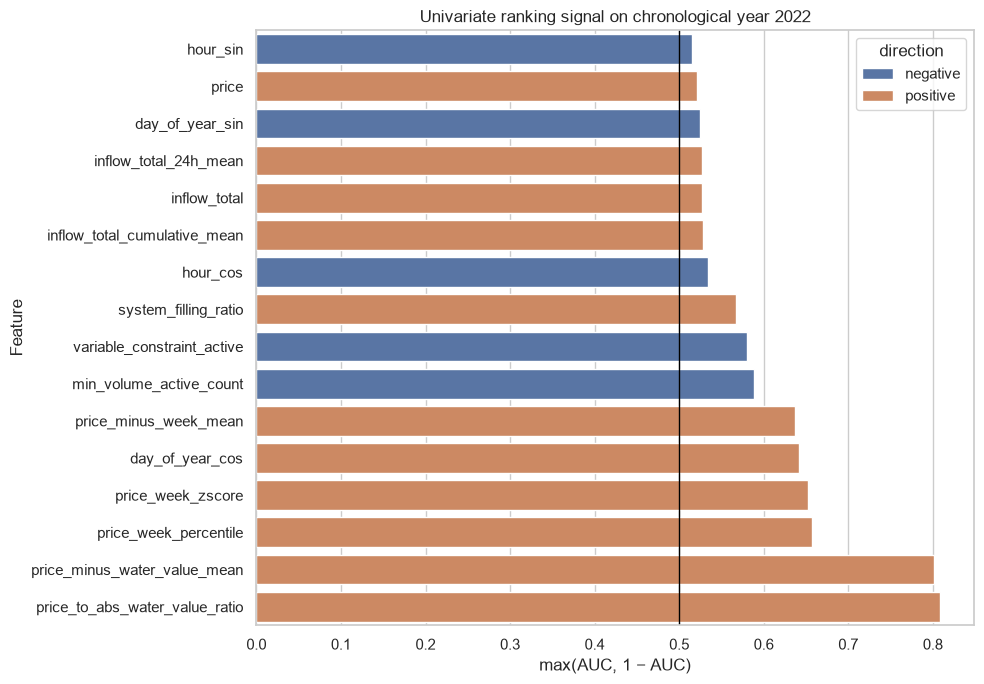

In [12]:
target_pattern = re.compile(r"^result_committed_(.+)_t(\d+)$")
target_units = list(dict.fromkeys(
    target_pattern.match(c).group(1)
    for c in targets.columns if target_pattern.match(c)
))
target_cube = np.stack([
    targets[[f"result_committed_{unit}_t{h}" for h in range(HORIZON)]]
    .to_numpy(dtype=np.int8)
    for unit in target_units
], axis=1)

case_2022 = pd.DatetimeIndex(train_cases["starttime"]).year == 2022
row_2022 = (
    (features["split"] == "train")
    & (features["starttime"].dt.year == 2022)
)
y_2022 = target_cube[case_2022].transpose(0, 2, 1).reshape(-1)

diagnostic_features = [
    "price",
    "price_week_percentile",
    "price_minus_week_mean",
    "price_week_zscore",
    "price_minus_water_value_mean",
    "price_to_abs_water_value_ratio",
    "system_filling_ratio",
    "inflow_total",
    "inflow_total_24h_mean",
    "inflow_total_cumulative_mean",
    "min_volume_active_count",
    "variable_constraint_active",
    "hour_sin",
    "hour_cos",
    "day_of_year_sin",
    "day_of_year_cos",
]

signal_rows = []
for column in diagnostic_features:
    x = np.repeat(features.loc[row_2022, column].to_numpy(), len(target_units))
    auc = roc_auc_score(y_2022, x)
    signal_rows.append({
        "feature": column,
        "auc": auc,
        "ranking_strength": max(auc, 1-auc),
        "direction": "positive" if auc >= .5 else "negative",
    })

univariate_signal = pd.DataFrame(signal_rows).sort_values(
    "ranking_strength", ascending=False
)
display(univariate_signal.style.format({"auc":"{:.3f}", "ranking_strength":"{:.3f}"}))

fig, ax = plt.subplots(figsize=(10, 7))
plot_signal = univariate_signal.sort_values("ranking_strength")
sns.barplot(data=plot_signal, x="ranking_strength", y="feature",
            hue="direction", dodge=False, ax=ax)
ax.axvline(.5, color="black", linewidth=1)
ax.set(title="Univariate ranking signal on chronological year 2022",
       xlabel="max(AUC, 1 − AUC)", ylabel="Feature")
fig.tight_layout()
fig.savefig(FIG_DIR/"feature_engineering_univariate_signal.png",
            dpi=160, bbox_inches="tight")
plt.show()


**Observation.** The opportunity-cost features are expected to dominate because EDA showed a nearly monotonic relationship between commitment and price relative to terminal water value. Weekly price rank, filling, and inflow provide complementary signals. Weak standalone calendar AUC does not justify dropping cyclic features: their value is conditional on price, season, unit, and physical state.


## 12. Recommended model feature sets

### Baseline set

Use calendar, raw price, weekly price summaries, mean terminal water value, price–water-value margin, system filling, total inflow, and aggregate constraints. This is small enough for logistic regression and provides an interpretable reference.

### Strong tree set

Use all non-constant engineered features. Train one LightGBM per unit first. Tree models do not require scaling and can select nonlinear interactions among reservoir, inflow, price, and constraints.

### Shared-model additions

For a pooled LightGBM, CatBoost, or TCN, add `unit`, `plant`, generator number, output limits, start/stop cost, and units per plant from `generator_features`.

### Optional dimensionality reduction

PCA may be tested on the correlated reservoir/inflow blocks for logistic regression or a neural model. It should be fitted only on each chronological training fold and then applied to validation/test. Keep the original interpretable features for tree models and SHAP.


In [13]:
constant_features = feature_audit.loc[
    feature_audit["constant"], "feature"
].tolist()
TREE_FEATURES = [c for c in model_features if c not in constant_features]

BASELINE_FEATURES = [
    "hour_sin", "hour_cos", "weekday_sin", "weekday_cos",
    "month_sin", "month_cos", "horizon_hour",
    "price", "price_week_mean", "price_week_std",
    "price_week_percentile", "price_minus_week_mean",
    "water_value_end_mean", "price_minus_water_value_mean",
    "system_filling_ratio", "inflow_total",
    "inflow_total_24h_mean", "min_flow_total",
    "min_volume_total", "variable_constraint_active",
]

assert not features[TREE_FEATURES].isna().any().any()
assert np.isfinite(features[TREE_FEATURES].to_numpy()).all()

print("Baseline features:", len(BASELINE_FEATURES))
print("Tree features:", len(TREE_FEATURES))
print("Static shared-model features:", len(generator_features.columns)-2,
      "+ categorical unit and plant")


Baseline features: 20
Tree features: 187
Static shared-model features: 9 + categorical unit and plant


## 13. Leakage checklist and next experiments

| Candidate | Use? | Reason |
|---|---:|---|
| `Run No` | No | Identifier and time proxy, not a physical predictor |
| Raw year | No initially | Encourages extrapolation from regime-specific labels |
| `total_calculation_time` | No | Solver output unavailable in test and potential leakage |
| Previous true unit states | No | Labels are unavailable throughout 2023–2024 |
| Full 168-hour price/inflow horizon | Yes | Legitimate input to the supplied scheduling case |
| End-of-horizon water value | Yes | Explicitly specified for a one-week scheduling problem |
| Target-encoded unit statistics | Only fold-safe | Must be computed from earlier training data only |
| Scaling/PCA | Model-dependent | Fit inside each chronological training fold |
| Train and test inputs for EDA | Yes | No labels are used; learned transforms remain fold-fitted |

### Experiments to run next

1. Compare `BASELINE_FEATURES` against raw-input LightGBM.
2. Add weekly price rank and local price windows.
3. Add water-value margins.
4. Add reservoir filling and inflow blocks.
5. Add individual environmental constraints.
6. Use fold-wise gain/permutation importance and SHAP to prune features.
7. Test a shared model with static generator features.
8. Blend only models whose chronological out-of-fold errors are meaningfully different.

A feature is promoted only when it improves mean and worst-fold micro ROC-AUC under the purged chronological validation scheme.
